In [1]:
import os
from glob import glob

for root, dirs, files in os.walk("/kaggle/input"):
    csvs = [f for f in files if f.endswith(".csv")]
    jpgs = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    if csvs or jpgs:
        print(root)
        print("   CSV files:", csvs)
        print("   image files:", len(jpgs))

/kaggle/input/datasets/salviohexia/isic-2019-skin-lesion-images-for-classification
   CSV files: ['ISIC_2019_Training_GroundTruth.csv', 'ISIC_2019_Training_Metadata.csv']
   image files: 0
/kaggle/input/datasets/salviohexia/isic-2019-skin-lesion-images-for-classification/AK
   CSV files: []
   image files: 867
/kaggle/input/datasets/salviohexia/isic-2019-skin-lesion-images-for-classification/BCC
   CSV files: []
   image files: 3323
/kaggle/input/datasets/salviohexia/isic-2019-skin-lesion-images-for-classification/BKL
   CSV files: []
   image files: 2624
/kaggle/input/datasets/salviohexia/isic-2019-skin-lesion-images-for-classification/DF
   CSV files: []
   image files: 239
/kaggle/input/datasets/salviohexia/isic-2019-skin-lesion-images-for-classification/MEL
   CSV files: []
   image files: 4522
/kaggle/input/datasets/salviohexia/isic-2019-skin-lesion-images-for-classification/NV
   CSV files: []
   image files: 12875
/kaggle/input/datasets/salviohexia/isic-2019-skin-lesion-images-f

In [2]:
import os
import pandas as pd
from glob import glob

root = "/kaggle/input/datasets/salviohexia/isic-2019-skin-lesion-images-for-classification"

# Labels and metadata
gt = pd.read_csv(f"{root}/ISIC_2019_Training_GroundTruth.csv")
meta = pd.read_csv(f"{root}/ISIC_2019_Training_Metadata.csv")
print("Ground truth shape:", gt.shape)
print("Metadata shape:", meta.shape)
print(gt.head(3))
print(meta.head(3))

# The ground truth stores labels "one-hot" (a 1 in the column of the right class).
# idxmax finds the column holding the 1, which gives us a single label per image.
classes = ["MEL", "NV", "BCC", "AK", "BKL", "DF", "VASC", "SCC"]
gt["dx"] = gt[classes].idxmax(axis=1)

# Join labels with metadata (age, sex, body site, lesion_id) on the image name
df = gt[["image", "dx"]].merge(meta, on="image", how="left")

# Find each image file on disk and attach its path
exts = (".jpg", ".jpeg", ".png")
all_files = [p for p in glob(f"{root}/**/*", recursive=True) if p.lower().endswith(exts)]
path_lookup = {os.path.splitext(os.path.basename(p))[0]: p for p in all_files}
df["path"] = df["image"].map(path_lookup)

# Checks
df["folder_label"] = df["path"].str.split("/").str[-2]
print()
print("Images found on disk:", len(all_files))
print("Rows with no image file:", df["path"].isna().sum())
print("CSV label disagrees with folder name:", (df["dx"] != df["folder_label"]).sum())
print()
print(df["dx"].value_counts())
print()
print("Missing values per column:")
print(df[["age_approx", "anatom_site_general", "sex", "lesion_id"]].isna().sum())

Ground truth shape: (25331, 10)
Metadata shape: (25331, 5)
          image  MEL   NV  BCC   AK  BKL   DF  VASC  SCC  UNK
0  ISIC_0000000  0.0  1.0  0.0  0.0  0.0  0.0   0.0  0.0  0.0
1  ISIC_0000001  0.0  1.0  0.0  0.0  0.0  0.0   0.0  0.0  0.0
2  ISIC_0000002  1.0  0.0  0.0  0.0  0.0  0.0   0.0  0.0  0.0
          image  age_approx anatom_site_general lesion_id     sex
0  ISIC_0000000        55.0      anterior torso       NaN  female
1  ISIC_0000001        30.0      anterior torso       NaN  female
2  ISIC_0000002        60.0     upper extremity       NaN  female

Images found on disk: 25331
Rows with no image file: 0
CSV label disagrees with folder name: 0

dx
NV      12875
MEL      4522
BCC      3323
BKL      2624
AK        867
SCC       628
VASC      253
DF        239
Name: count, dtype: int64

Missing values per column:
age_approx              437
anatom_site_general    2631
sex                     384
lesion_id              2084
dtype: int64


In [3]:
pad_root = "/kaggle/input/datasets/mahdavi1202/skin-cancer"

pad = pd.read_csv(f"{pad_root}/metadata.csv")
print("Shape:", pad.shape)
print()
print("Columns:")
print(list(pad.columns))
print()
print(pad.head(3).T)

Shape: (2298, 26)

Columns:
['patient_id', 'lesion_id', 'smoke', 'drink', 'background_father', 'background_mother', 'age', 'pesticide', 'gender', 'skin_cancer_history', 'cancer_history', 'has_piped_water', 'has_sewage_system', 'fitspatrick', 'region', 'diameter_1', 'diameter_2', 'diagnostic', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'img_id', 'biopsed']

                                         0                   1  \
patient_id                        PAT_1516              PAT_46   
lesion_id                             1765                 881   
smoke                                  NaN               False   
drink                                  NaN               False   
background_father                      NaN           POMERANIA   
background_mother                      NaN           POMERANIA   
age                                      8                  55   
pesticide                              NaN               False   
gender                           

In [4]:
# Run this second cell after you've seen the columns.
# I expect the diagnosis column to be called "diagnostic",
# the patient column "patient_id", and the filename column "img_id".
print(pad["diagnostic"].value_counts())
print()
print("Unique patients:", pad["patient_id"].nunique())
print("Unique lesions:", pad["lesion_id"].nunique())
print()
print("Images per patient:")
print(pad.groupby("patient_id").size().value_counts().sort_index())

diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64

Unique patients: 1373
Unique lesions: 1641

Images per patient:
1     829
2     328
3     132
4      42
5      21
6      12
7       6
10      3
Name: count, dtype: int64


In [5]:
# ---------- ISIC 2019 part (df comes from our earlier cell) ----------
isic = df[["image", "dx", "lesion_id", "path"]].copy()
isic = isic.rename(columns={"image": "image_id"})
isic["source"] = "isic2019"
# Group id = lesion_id if we have it, otherwise the image's own name
isic["group_id"] = "isic_" + isic["lesion_id"].fillna(isic["image_id"]).astype(str)
isic = isic[["image_id", "path", "dx", "source", "group_id"]]

# ---------- PAD-UFES-20 part ----------
pad_root = "/kaggle/input/datasets/mahdavi1202/skin-cancer"
exts = (".png", ".jpg", ".jpeg")
pad_files = [p for p in glob(f"{pad_root}/**/*", recursive=True) if p.lower().endswith(exts)]
pad_lookup = {os.path.basename(p): p for p in pad_files}   # keeps the extension

pad["path"] = pad["img_id"].map(pad_lookup)

label_map = {"ACK": "AK", "BCC": "BCC", "MEL": "MEL",
             "NEV": "NV", "SCC": "SCC", "SEK": "BKL"}

pad_t = pd.DataFrame({
    "image_id": pad["img_id"],
    "path": pad["path"],
    "dx": pad["diagnostic"].map(label_map),
    "source": "pad_ufes20",
    "group_id": "pad_" + pad["patient_id"].astype(str),
})

# ---------- combine ----------
full = pd.concat([isic, pad_t], ignore_index=True)

# ---------- checks ----------
print("PAD images found on disk:", len(pad_files))
print("Total rows:", len(full))
print("Rows with no image path:", full["path"].isna().sum())
print("Rows with no label:", full["dx"].isna().sum())
print("Duplicate image names:", full["image_id"].duplicated().sum())
print()
print("Images per class and source:")
print(pd.crosstab(full["dx"], full["source"], margins=True))
print()
print("Class share inside each source (%):")
print((pd.crosstab(full["dx"], full["source"], normalize="columns") * 100).round(1))

PAD images found on disk: 2298
Total rows: 27629
Rows with no image path: 0
Rows with no label: 0
Duplicate image names: 0

Images per class and source:
source  isic2019  pad_ufes20    All
dx                                 
AK           867         730   1597
BCC         3323         845   4168
BKL         2624         235   2859
DF           239           0    239
MEL         4522          52   4574
NV         12875         244  13119
SCC          628         192    820
VASC         253           0    253
All        25331        2298  27629

Class share inside each source (%):
source  isic2019  pad_ufes20
dx                          
AK           3.4        31.8
BCC         13.1        36.8
BKL         10.4        10.2
DF           0.9         0.0
MEL         17.9         2.3
NV          50.8        10.6
SCC          2.5         8.4
VASC         1.0         0.0


In [6]:
from PIL import Image

for src in full["source"].unique():
    sample = full[full["source"] == src].sample(150, random_state=0)
    sizes = [Image.open(p).size for p in sample["path"]]
    print(src)
    print(pd.Series(sizes).value_counts().head(5))
    print()

isic2019
(1024, 1024)    73
(600, 450)      60
(1024, 680)      9
(1024, 768)      6
(767, 576)       1
Name: count, dtype: int64

pad_ufes20
(640, 640)    7
(750, 750)    3
(757, 757)    2
(394, 394)    2
(441, 441)    2
Name: count, dtype: int64



In [7]:
from sklearn.model_selection import StratifiedGroupKFold

# One label that combines class and source, so both are balanced across the splits
full["strat"] = full["dx"] + "|" + full["source"]

# Step 1: carve out the TEST set (about 1/7 of the data = 14%)
sgkf1 = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
trainval_idx, test_idx = next(sgkf1.split(full, full["strat"], groups=full["group_id"]))
trainval = full.iloc[trainval_idx]
test = full.iloc[test_idx]

# Step 2: from the rest, carve out the VALIDATION set (1/6 of 6/7 = 1/7 = 14%)
sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
train_idx, val_idx = next(sgkf2.split(trainval, trainval["strat"], groups=trainval["group_id"]))
train = trainval.iloc[train_idx]
val = trainval.iloc[val_idx]

# Record the result in a column
full["split"] = "train"
full.loc[val.index, "split"] = "val"
full.loc[test.index, "split"] = "test"

# ---------- Checks ----------
print("Rows per split:")
print(full["split"].value_counts())
print()

groups = {s: set(full.loc[full["split"] == s, "group_id"]) for s in ["train", "val", "test"]}
print("Groups shared between train and val: ", len(groups["train"] & groups["val"]))
print("Groups shared between train and test:", len(groups["train"] & groups["test"]))
print("Groups shared between val and test:  ", len(groups["val"] & groups["test"]))
print()

print("Class counts per split (all sources):")
print(pd.crosstab(full["dx"], full["split"])[["train", "val", "test"]])
print()
print("Class counts per split (PAD-UFES-20 phone photos only):")
pad_only = full[full["source"] == "pad_ufes20"]
print(pd.crosstab(pad_only["dx"], pad_only["split"])[["train", "val", "test"]])

# Save so the split survives if the session restarts
full.drop(columns="strat").to_csv("/kaggle/working/full_split.csv", index=False)
print()
print("Saved to /kaggle/working/full_split.csv")

Rows per split:
split
train    19689
val       3981
test      3959
Name: count, dtype: int64

Groups shared between train and val:  0
Groups shared between train and test: 0
Groups shared between val and test:   0

Class counts per split (all sources):
split  train   val  test
dx                      
AK      1160   235   202
BCC     2830   771   567
BKL     2039   394   426
DF       171    29    39
MEL     3324   588   662
NV      9358  1845  1916
SCC      610    97   113
VASC     197    22    34

Class counts per split (PAD-UFES-20 phone photos only):
split  train  val  test
dx                     
AK       519  119    92
BCC      607  127   111
BKL      164   33    38
MEL       34    5    13
NV       173   38    33
SCC      144   18    30

Saved to /kaggle/working/full_split.csv


In [8]:
from PIL import Image
from concurrent.futures import ProcessPoolExecutor

full = pd.read_csv("/kaggle/working/full_split.csv")
out_dir = "/kaggle/working/imgs256"
os.makedirs(out_dir, exist_ok=True)

def shrink(job):
    src, dst = job
    if os.path.exists(dst):
        return
    img = Image.open(src).convert("RGB")
    w, h = img.size
    scale = 256 / min(w, h)                       # make the SHORTER side 256 pixels
    img = img.resize((round(w * scale), round(h * scale)), Image.LANCZOS)
    w, h = img.size
    left, top = (w - 256) // 2, (h - 256) // 2    # cut the centre 256x256 square
    img = img.crop((left, top, left + 256, top + 256))
    img.save(dst, quality=95)

full["small_path"] = [
    f"{out_dir}/{s}_{os.path.splitext(i)[0]}.jpg"
    for s, i in zip(full["source"], full["image_id"])
]

jobs = list(zip(full["path"], full["small_path"]))
with ProcessPoolExecutor(max_workers=4) as ex:
    list(ex.map(shrink, jobs, chunksize=64))

print("Small images created:", len(os.listdir(out_dir)))
full.to_csv("/kaggle/working/full_split.csv", index=False)

Small images created: 27629


In [9]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

# Turn class names into numbers: the model outputs numbers, not text
class_names = sorted(full["dx"].unique())
class_to_idx = {c: i for i, c in enumerate(class_names)}
print(class_to_idx)

# ImageNet statistics: the pretrained ResNet50 expects inputs scaled this way
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = T.Compose([
    T.RandomResizedCrop(224, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(180),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    T.ToTensor(),
    T.Normalize(mean, std),
])

eval_tf = T.Compose([
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(mean, std),
])

class SkinDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, i):
        row = self.frame.iloc[i]
        img = Image.open(row["small_path"]).convert("RGB")
        return self.transform(img), class_to_idx[row["dx"]]

train_ds = SkinDataset(full[full["split"] == "train"], train_tf)
val_ds   = SkinDataset(full[full["split"] == "val"],   eval_tf)
test_ds  = SkinDataset(full[full["split"] == "test"],  eval_tf)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True,  num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=64, shuffle=False, num_workers=4, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False, num_workers=4, pin_memory=True)

images, labels = next(iter(train_loader))
print("Batch of images:", images.shape)
print("Batch of labels:", labels.shape)

{'AK': 0, 'BCC': 1, 'BKL': 2, 'DF': 3, 'MEL': 4, 'NV': 5, 'SCC': 6, 'VASC': 7}
Batch of images: torch.Size([64, 3, 224, 224])
Batch of labels: torch.Size([64])


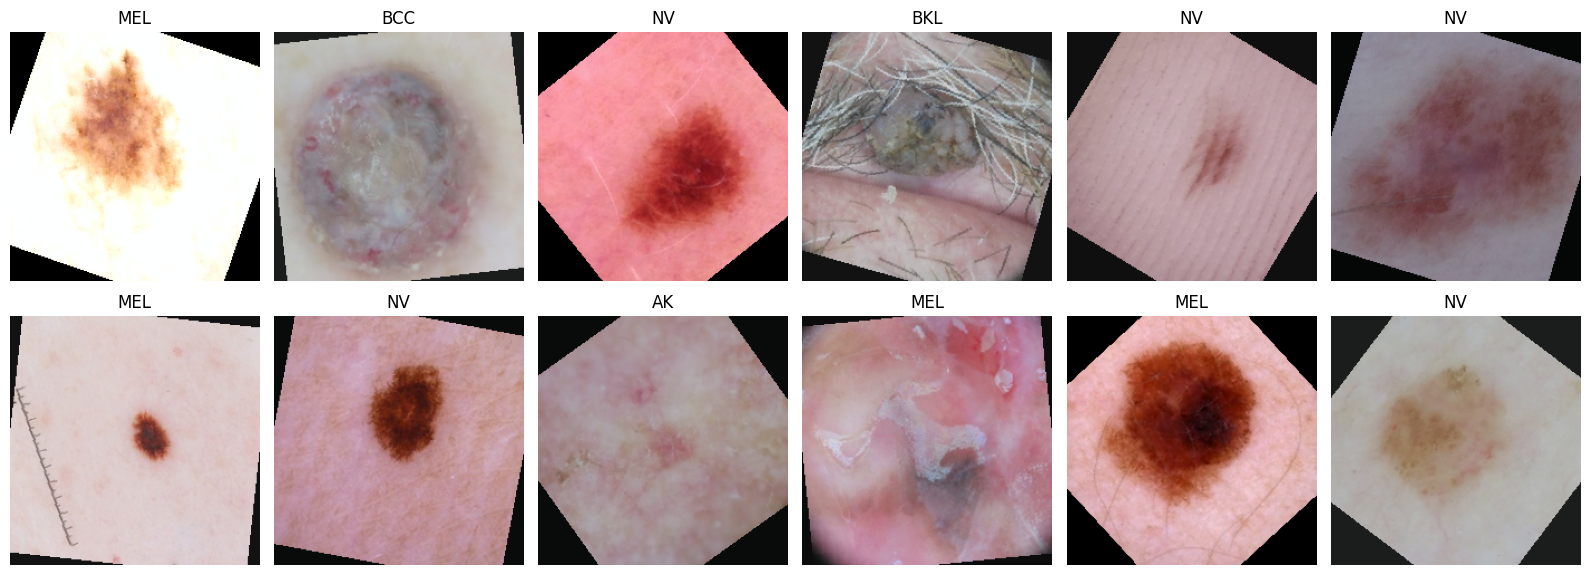

In [10]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, img, lab in zip(axes.flat, images[:12], labels[:12]):
    img = img.permute(1, 2, 0).numpy() * np.array(std) + np.array(mean)   # undo normalization
    ax.imshow(np.clip(img, 0, 1))
    ax.set_title(class_names[lab])
    ax.axis("off")
plt.tight_layout()
plt.show()